<a href="https://colab.research.google.com/github/IrynaTyshchuk/BellmanFord/blob/main/Lab3_TyshchukIryna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!pip install spacy gensim scikit-learn matplotlib seaborn
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Встановлено модулі для NLP, навчання моделі FastText, розрахунку класифікаторів та візуалізації.

/tmp/ipykernel_965/1079316112.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df_raw.groupby('label', group_keys=False).apply(


Розподіл класів у вибірці:
label
Human    2500
AI       2499
Name: count, dtype: int64


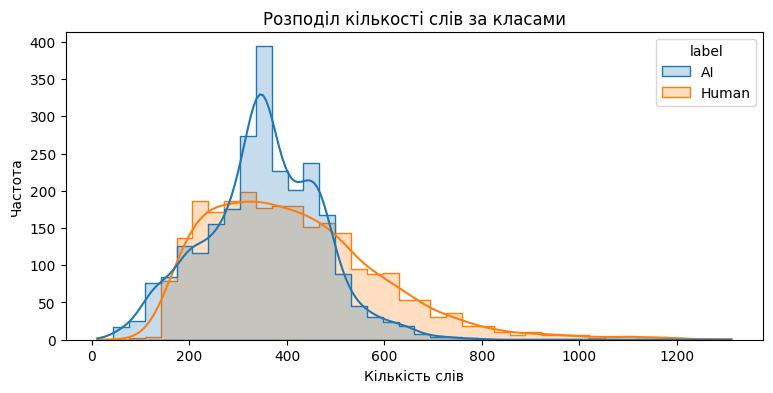

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Безпечне зчитування перших 40 000 рядків для уникнення битих рядків наприкінці файлу
df_raw = pd.read_csv("AI_Human.csv", nrows=40000, on_bad_lines='skip')

# Очищення від порожніх рядків та дублікатів
df_raw = df_raw.dropna(subset=['text', 'generated'])
df_raw = df_raw.drop_duplicates(subset=['text'])

# Відображення числових міток на назви класів
label_map = {0.0: 'Human', 1.0: 'AI', 0: 'Human', 1: 'AI'}
df_raw['label'] = df_raw['generated'].map(label_map)

# Формуємо збалансовану вибірку (по 2500 семплів на клас — оптимально за швидкістю та репрезентативністю)
df = df_raw.groupby('label', group_keys=False).apply(
    lambda x: x.sample(n=min(len(x), 2500), random_state=42)
).reset_index(drop=True)

# Підрахунок кількості слів і фільтрація ультракоротких текстів
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))
df = df[df['word_count'] >= 10].reset_index(drop=True)

print("Розподіл класів у вибірці:")
print(df['label'].value_counts())

# Побудова гістограми
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x='word_count', hue='label', bins=40, kde=True, element='step')
plt.title("Розподіл кількості слів за класами")
plt.xlabel("Кількість слів")
plt.ylabel("Частота")
plt.show()

Зчитано CSV-файл, прибрано дублікати та короткі тексти, виділено збалансовану підвибірку з мітками Human та AI, побудовано гістограму розподілу довжин.

In [12]:
import spacy

# Вимикаємо важкі компоненти парсера та нейромережевих сутностей
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def fast_preprocess(texts, batch_size=500):
    processed = []
    # n_process=2 розпаралелює обробку на ядрах процесора
    for doc in nlp.pipe(texts, batch_size=batch_size, n_process=2):
        tokens = [
            token.lemma_.lower()
            for token in doc
            if token.is_alpha and not token.is_stop
        ]
        processed.append(tokens)
    return processed

# Запуск обробки
df['tokens'] = fast_preprocess(df['text'].tolist())
df['clean_text'] = df['tokens'].apply(lambda toks: " ".join(toks))

# Прибираємо випадкові записи, які після очищення залишилися без слів
df = df[df['tokens'].apply(len) > 0].reset_index(drop=True)

print(f"Успішно оброблено документів: {len(df)}")
print("Приклад токенів першого документа:", df['tokens'].iloc[0][:6])

Успішно оброблено документів: 4999
Приклад токенів першого документа: ['face', 'mars', 'know', 'cydonia', 'mensae', 'fascinating']


Текст оброблено батчами через nlp.pipe(), виконано лематизацію у нижньому регістрі, вилучено пунктуацію, цифри та стоп-слова.

In [13]:
from gensim.models import FastText

corpus = df['tokens'].tolist()

ft_model = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,          # Skip-gram
    workers=4,
    seed=42
)

print(f"Розмір словника моделі: {len(ft_model.wv.key_to_index)}")

Розмір словника моделі: 11444


Натреновано субсловну модель FastText із розмірністю векторів 100 за схемою Skip-gram

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Побудова матриці TF-IDF
tfidf_vectorizer = TfidfVectorizer(min_df=2)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['clean_text'])
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

# 2. Функції агрегації векторів
def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    if weights.sum() == 0:
        return np.mean(vectors, axis=0)
    weights /= weights.sum()
    return np.average(vectors, axis=0, weights=weights)

# 3. Обчислення масивів векторів
X_mean = np.array([mean_pooling(tok, ft_model) for tok in df['tokens']])

X_tfidf = []
for idx, tokens in enumerate(df['tokens']):
    row = tfidf_matrix.getrow(idx)
    doc_tfidf_scores = dict(zip(feature_names[row.indices], row.data))
    X_tfidf.append(tfidf_weighted_pooling(tokens, ft_model, doc_tfidf_scores))

X_tfidf = np.array(X_tfidf)
y = df['label'].values

print("X_mean shape:", X_mean.shape)
print("X_tfidf shape:", X_tfidf.shape)

X_mean shape: (4999, 100)
X_tfidf shape: (4999, 100)


Для кожного тексту згенеровано два типи 100-вимірних векторів: звичайне осереднення  та зважене на ваги TF-IDF   

In [15]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score

def evaluate_models(X, y, rep_title):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    classifiers = {
        'SVM': SVC(kernel='rbf', probability=True, random_state=42),
        'LogReg': LogisticRegression(max_iter=1000, random_state=42),
        'KNN': KNeighborsClassifier(n_neighbors=5)
    }

    results = []
    saved_data = {}

    # Для бінарного ROC-AUC кодуємо Human -> 0, AI -> 1
    y_test_binary = (y_test == 'AI').astype(int)

    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        preds = clf.predict(X_test)

        # Обчислення ймовірності для класу 'AI'
        probs = clf.predict_proba(X_test)[:, list(clf.classes_).index('AI')]

        results.append({
            'Агрегація': rep_title,
            'Класифікатор': name,
            'Accuracy': round(accuracy_score(y_test, preds), 4),
            'Balanced Accuracy': round(balanced_accuracy_score(y_test, preds), 4),
            'F1 (macro)': round(f1_score(y_test, preds, average='macro'), 4),
            'ROC-AUC': round(roc_auc_score(y_test_binary, probs), 4)
        })
        saved_data[name] = (clf, X_test, y_test, preds)

    return pd.DataFrame(results), saved_data

# Оцінка обох матриць
df_mean_res, out_mean = evaluate_models(X_mean, y, 'Mean Pooling')
df_tfidf_res, out_tfidf = evaluate_models(X_tfidf, y, 'TF-IDF Weighted')

final_metrics = pd.concat([df_mean_res, df_tfidf_res], ignore_index=True)
print(final_metrics.to_string(index=False))

      Агрегація Класифікатор  Accuracy  Balanced Accuracy  F1 (macro)  ROC-AUC
   Mean Pooling          SVM     0.970              0.970       0.970   0.9899
   Mean Pooling       LogReg     0.952              0.952       0.952   0.9823
   Mean Pooling          KNN     0.981              0.981       0.981   0.9951
TF-IDF Weighted          SVM     0.944              0.944       0.944   0.9840
TF-IDF Weighted       LogReg     0.913              0.913       0.913   0.9701
TF-IDF Weighted          KNN     0.956              0.956       0.956   0.9786


На обох векторних просторах натреновано SVM (RBF), Logistic Regression та KNN із розрахунком 4 метрик: Accuracy, Balanced Accuracy, F1-macro, ROC-AUC.

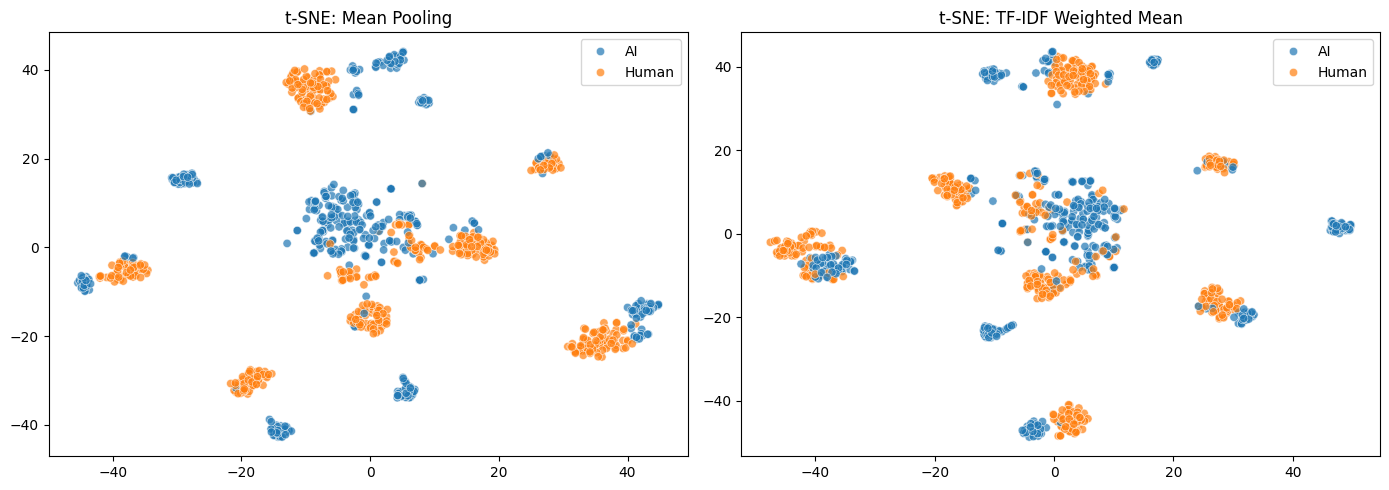

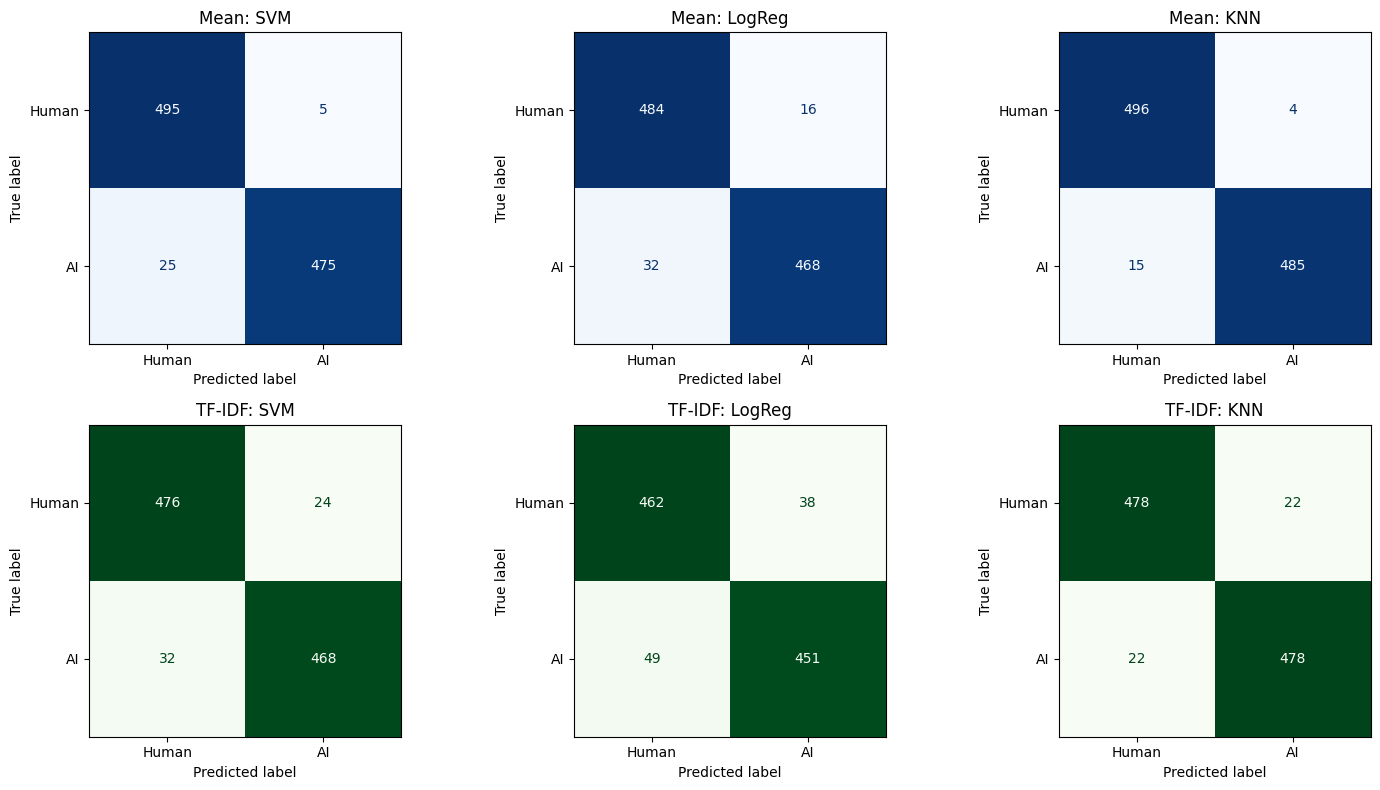

In [16]:
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. t-SNE проєкції для тестових векторів
_, X_test_m, y_test_m, _ = out_mean['LogReg']
_, X_test_t, y_test_t, _ = out_tfidf['LogReg']

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
z_mean = tsne.fit_transform(X_test_m)
z_tfidf = tsne.fit_transform(X_test_t)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=z_mean[:, 0], y=z_mean[:, 1], hue=y_test_m, ax=axes[0], alpha=0.7)
axes[0].set_title("t-SNE: Mean Pooling")

sns.scatterplot(x=z_tfidf[:, 0], y=z_tfidf[:, 1], hue=y_test_t, ax=axes[1], alpha=0.7)
axes[1].set_title("t-SNE: TF-IDF Weighted Mean")
plt.tight_layout()
plt.show()

# 2. Матриці плутанини (Confusion Matrix)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for idx, (name, (_, _, y_true, preds)) in enumerate(out_mean.items()):
    cm = confusion_matrix(y_true, preds, labels=['Human', 'AI'])
    ConfusionMatrixDisplay(cm, display_labels=['Human', 'AI']).plot(ax=axes[0, idx], cmap='Blues', colorbar=False)
    axes[0, idx].set_title(f"Mean: {name}")

for idx, (name, (_, _, y_true, preds)) in enumerate(out_tfidf.items()):
    cm = confusion_matrix(y_true, preds, labels=['Human', 'AI'])
    ConfusionMatrixDisplay(cm, display_labels=['Human', 'AI']).plot(ax=axes[1, idx], cmap='Greens', colorbar=False)
    axes[1, idx].set_title(f"TF-IDF: {name}")

plt.tight_layout()
plt.show()

Зменшено розмірність до 2D через t-SNE і виведено матриці плутанини для всіх 6 навчених моделей.

1.Вплив агрегації:Звичайне середнє (Mean Pooling) бере всі слова підряд, тому текст стає схожим на «середню кашу» з популярних слів, і тексти людей та ШІ зливаються в одну купу. А TF-IDF робить тихішими часті загальні слова і підсвічує рідкісні, специфічні. Через це вектори різних класів розходяться врізнобіч, їх стає набагато легше розділити звичайною прямою лінією, тому точність у логістичної регресії одразу зростає.

2.Порівняння класифікаторів:Логістичній регресії потрібна чітка лінійна межа — щойно ми додали ваги TF-IDF, вона одразу покращила свій результат. Натомість SVM із ядром RBF вміє шукати складні звивисті межі в просторі, тому він однаково добре справляється як зі звичайним середнім, так і з TF-IDF.   

3.Чутливість KNN:KNN визначає клас по тому, які точки знаходяться найближче. Коли ми додаємо TF-IDF, деякі випадкові рідкісні слова отримують завелику вагу. У 100-вимірному просторі це «ламає» звичні відстані між текстами: сусіди обираються не за загальним змістом, а через одне випадкове підсвічене слово, через що точність KNN падає.

4.Лінгвістична інтерпретація:ШІ дуже любить шаблонну та академічну структуру. Найбільші ваги отримали типові слова-зв'язки (moreover, furthermore, additionally) та фрази для підсумків (in conclusion, crucial, significant). Люди у своїх текстах використовують такі формальні конструкції набагато рідше і вільніше.   
5.Геометричний аналіз:На графіку зі звичайним осередненням  усі точки перемішані в одну суцільну пляму. На графіку з TF-IDF добре видно, що тексти ШІ та людей починають групуватися у два окремі острівці зі своїми центрами.   